<a href="https://colab.research.google.com/github/Zheleikina/ML/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [ ]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [ ]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [ ]:
# Ваш код тут

import pandas as pd

display(df.tail(10))

df["date"] = pd.to_datetime(df["date"])
print(f"Мінімальна дата: {df['date'].min().date()}")
print(f"Максимальна дата: {df['date'].max().date()}")

stats = df["sales"].agg(["mean", "median", "std", "min", "max"])
display(stats.to_frame("sales_stats"))

duplicates = df["date"].duplicated().sum()
print(f"Кількість дублікатів дат: {duplicates}")

,date,sales
1451,2025-12-22,171.328008
1452,2025-12-23,156.237492
1453,2025-12-24,160.161011
1454,2025-12-25,141.622914
1455,2025-12-26,130.154195
1456,2025-12-27,164.792801
1457,2025-12-28,172.113885
1458,2025-12-29,170.054977
1459,2025-12-30,160.035508
1460,2025-12-31,144.925047


Мінімальна дата: 2022-01-01
Максимальна дата: 2025-12-31


,sales_stats
mean,128.868405
median,128.307405
std,19.969577
min,78.054031
max,279.572480


Кількість дублікатів дат: 0


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [ ]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [ ]:
# Ваш код тут

df_task = df.copy()

gap_positions = [50, 250, 500, 800, 1200]
gap_dates = df_task.index[gap_positions]
df_task.loc[gap_dates, "sales"] = np.nan

comparison = pd.DataFrame(index=gap_dates)
comparison["ffill"] = df_task["sales"].ffill().loc[gap_dates]
comparison["linear"] = df_task["sales"].interpolate(method="linear").loc[gap_dates]
comparison["time"] = df_task["sales"].interpolate(method="time").loc[gap_dates]

display(comparison)

print("Висновок: ffill заповнює пропуски попередніми значеннями, а лінійна та часова інтерполяція оцінюють їх на основі сусідніх значень. Для часового ряду доцільно використовувати часову інтерполяцію, оскільки вона враховує часові проміжки між датами.")

,ffill,linear,time
date,,,
2022-02-20,107.109464,112.217676,112.217676
2022-09-08,98.663180,98.094055,98.094055
2023-05-16,126.828583,128.193839,128.193839
2024-03-11,154.917374,146.277717,146.277717
2025-04-15,169.680889,155.852006,155.852006


Висновок: ffill заповнює пропуски попередніми значеннями, а лінійна та часова інтерполяція оцінюють їх на основі сусідніх значень. Для часового ряду доцільно використовувати часову інтерполяцію, оскільки вона враховує часові проміжки між датами.


## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

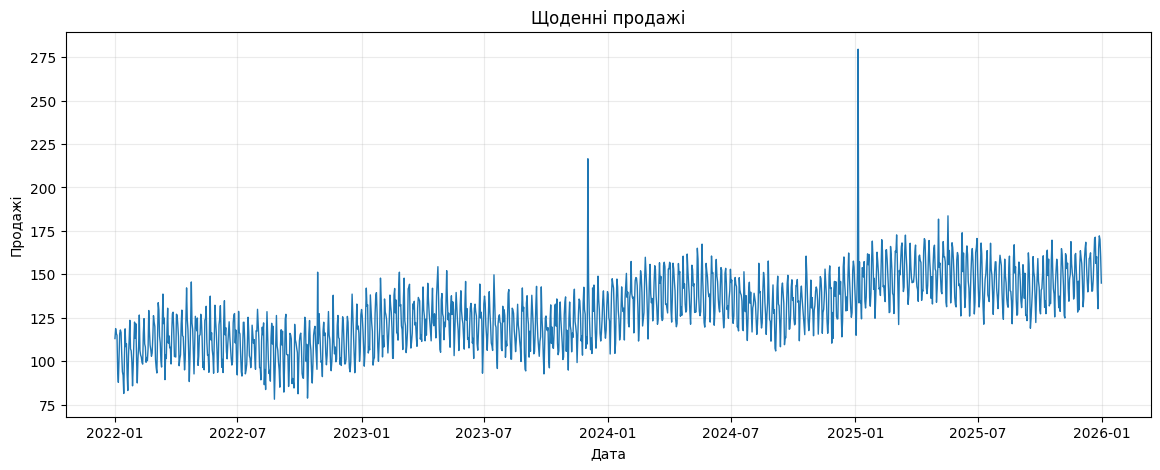

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

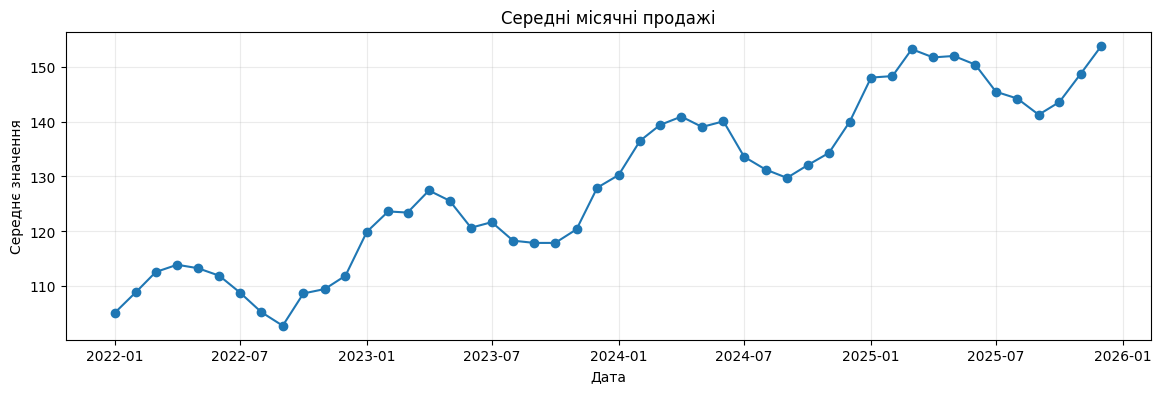

In [ ]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

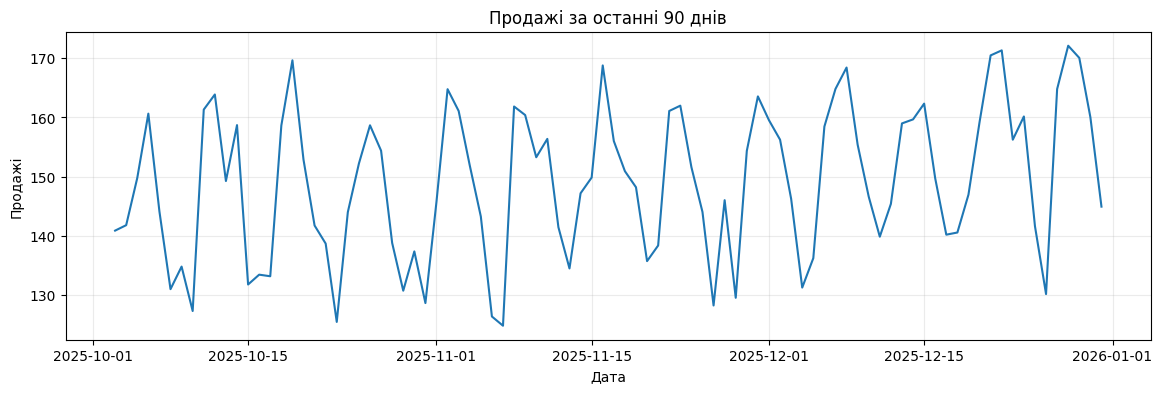

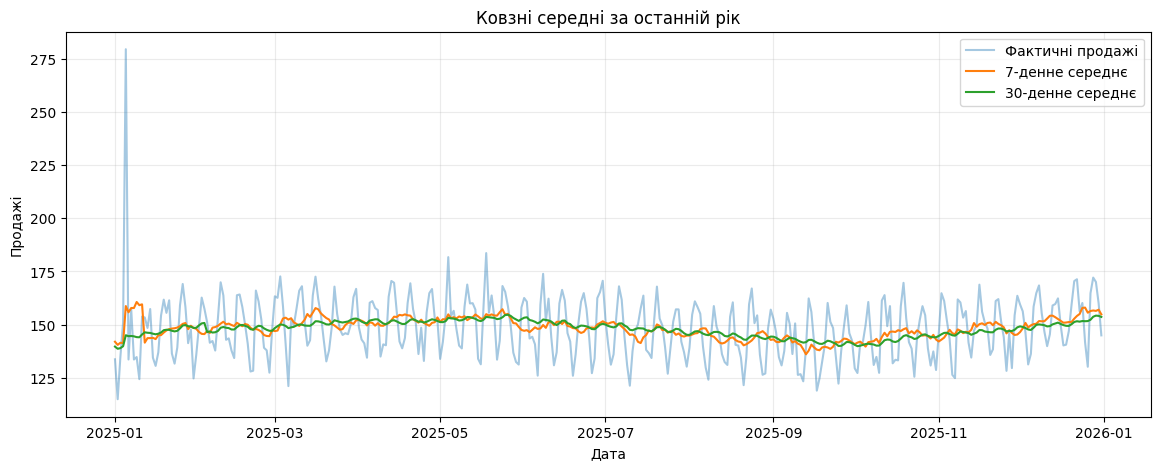

7-денне ковзне середнє краще відображає короткострокові зміни продажів, а 30-денне згладжує коливання та допомагає визначити загальну тенденцію.


In [ ]:
# Ваш код тут

last_90 = df["sales"].iloc[-90:]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(last_90.index, last_90.values)
ax.set_title("Продажі за останні 90 днів")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

rolling_7 = df["sales"].rolling(window=7).mean()
rolling_30 = df["sales"].rolling(window=30).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index[-365:], df["sales"].iloc[-365:], alpha=0.4, label="Фактичні продажі")
ax.plot(rolling_7.index[-365:], rolling_7.iloc[-365:], label="7-денне середнє")
ax.plot(rolling_30.index[-365:], rolling_30.iloc[-365:], label="30-денне середнє")
ax.set_title("Ковзні середні за останній рік")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print("7-денне ковзне середнє краще відображає короткострокові зміни продажів, а 30-денне згладжує коливання та допомагає визначити загальну тенденцію.")

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

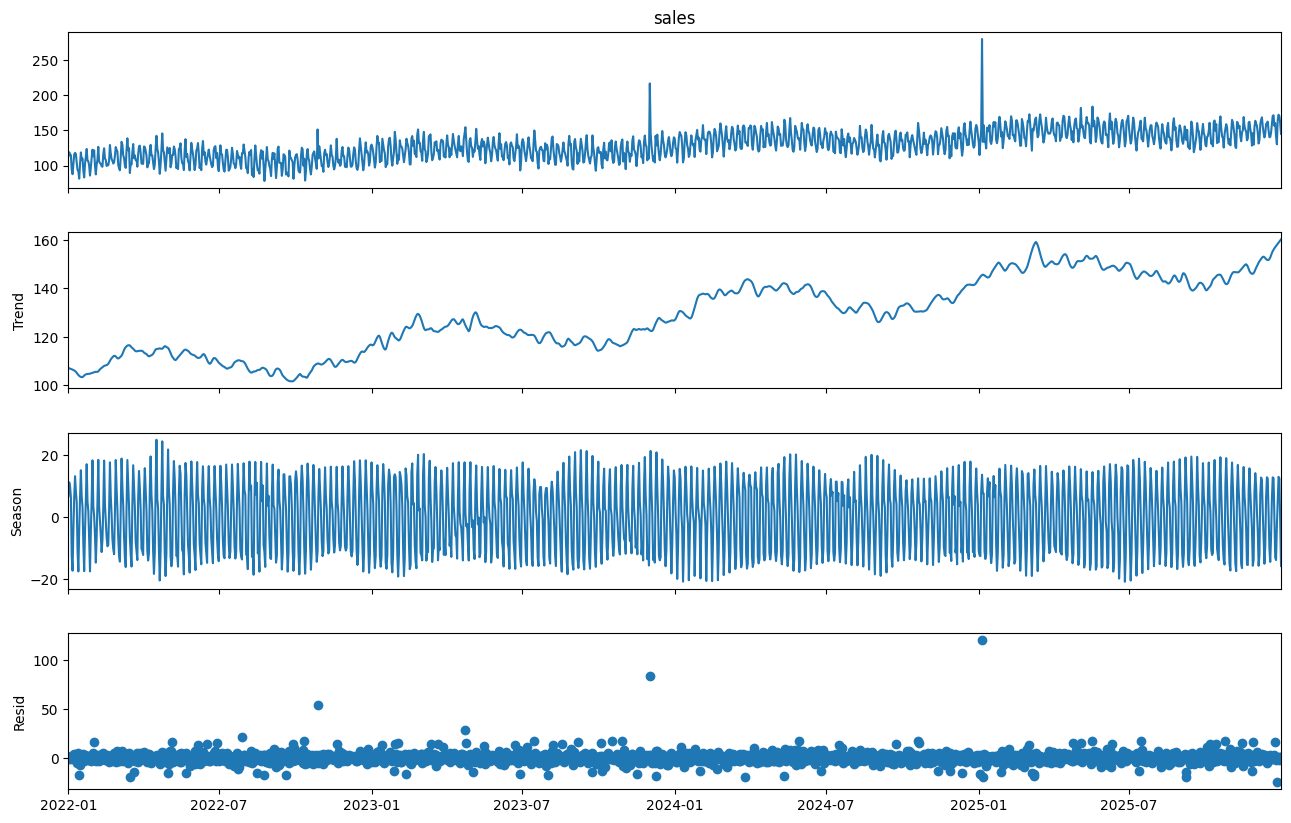

In [ ]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

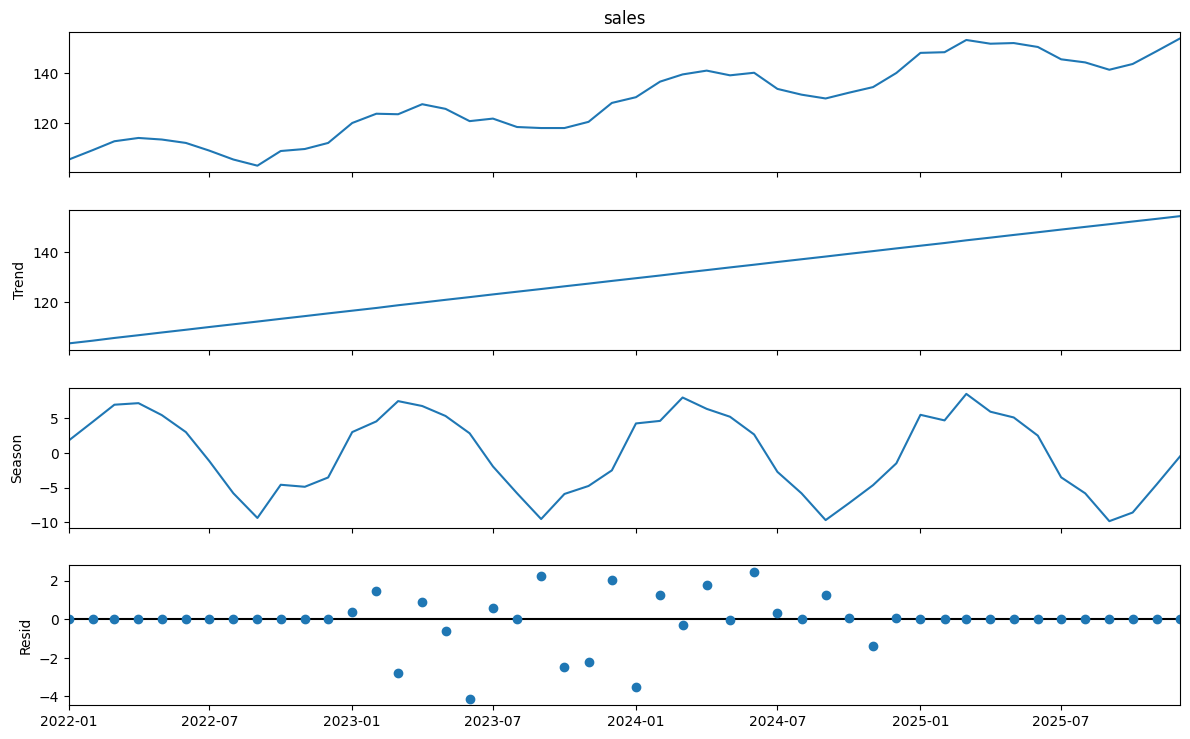

Для місячних даних обрано період сезонності 12, оскільки він відповідає річному циклу. Тренд показує загальний напрям зміни продажів у часі. Залишки відображають випадкові коливання, які не пояснюються трендом і сезонністю.


In [ ]:
# Ваш код тут

monthly_sales = df["sales"].resample("MS").mean()

stl_result = STL(monthly_sales, period=12, robust=True).fit()

fig = stl_result.plot()
fig.set_size_inches(13, 8)
plt.show()

print("Для місячних даних обрано період сезонності 12, оскільки він відповідає річному циклу. Тренд показує загальний напрям зміни продажів у часі. Залишки відображають випадкові коливання, які не пояснюються трендом і сезонністю.")

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [ ]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


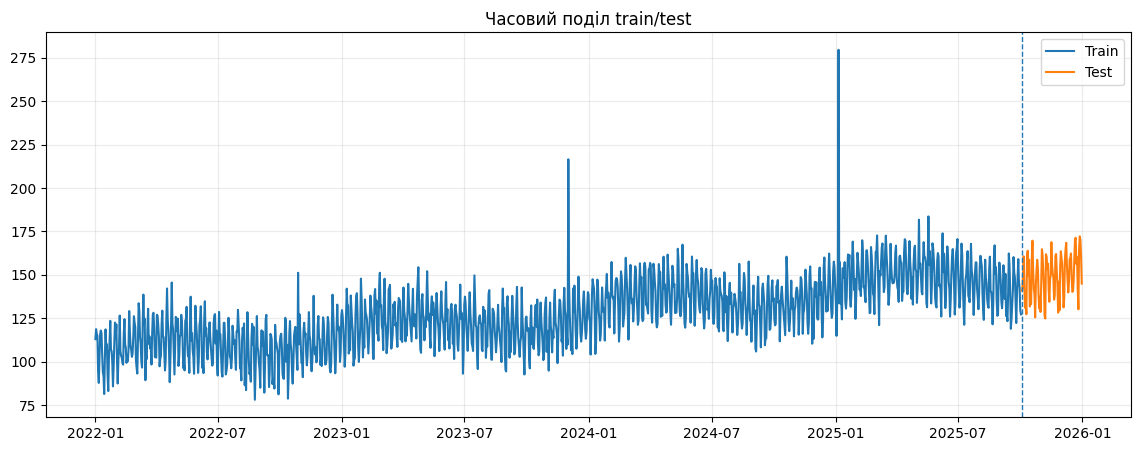

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [ ]:
# Ваш код тут

test_days = 60

train_60 = df.iloc[:-test_days].copy()
test_60 = df.iloc[-test_days:].copy()

print("Кількість записів train:", train_60.shape[0])
print("Кількість записів test:", test_60.shape[0])
print("Остання дата train:", train_60.index[-1].date())
print("Перша дата test:", test_60.index[0].date())

Кількість записів train: 1401
Кількість записів test: 60
Остання дата train: 2025-11-01
Перша дата test: 2025-11-02


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [ ]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-10-03,140.875312,127.213304,137.575710
2025-10-04,141.794922,127.213304,148.849817
2025-10-05,149.768594,127.213304,159.044241
2025-10-06,160.638161,127.213304,145.953075
2025-10-07,144.109047,127.213304,142.430282


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [ ]:
# Ваш код тут

naive_result = evaluate(test["sales"], naive_pred, train["sales"], 7)
seasonal_result = evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)

metrics_table = pd.DataFrame(
    [naive_result, seasonal_result],
    index=["Naive", "Seasonal naive"]
)

display(metrics_table)

best_model = metrics_table["MAE"].idxmin()
print("Краща базова модель за MAE:", best_model)

actual_first = test["sales"].iloc[:30]
actual_last = test["sales"].iloc[-30:]

pred_first = baseline.loc[actual_first.index, "seasonal_naive"]
pred_last = baseline.loc[actual_last.index, "seasonal_naive"]

print("MAE за перші 30 днів:", round(mean_absolute_error(actual_first, pred_first), 3))
print("MAE за останні 30 днів:", round(mean_absolute_error(actual_last, pred_last), 3))

print("Висновок не варто робити лише за однією метрикою: MAE показує середню абсолютну помилку, RMSE сильніше враховує великі помилки, sMAPE оцінює відносну похибку, а MASE порівнює точність із базовим прогнозом.")

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955


Краща базова модель за MAE: Seasonal naive
MAE за перші 30 днів: 8.155
MAE за останні 30 днів: 6.768
Висновок не варто робити лише за однією метрикою: MAE показує середню абсолютну помилку, RMSE сильніше враховує великі помилки, sMAPE оцінює відносну похибку, а MASE порівнює точність із базовим прогнозом.


## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [ ]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


{'MAE': 13.11452610803631,
 'RMSE': np.float64(15.229020700077848),
 'sMAPE_%': np.float64(9.14961742586639),
 'MASE': np.float64(1.8499146745742305)}

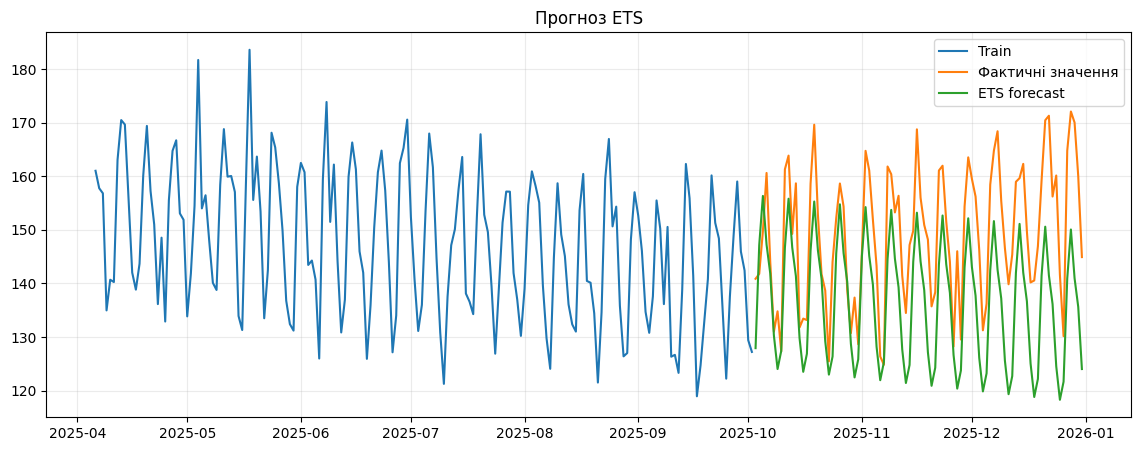

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [ ]:
# Ваш код тут

ets_simple = ExponentialSmoothing(
    train["sales"],
    trend=None,
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_simple_pred = ets_simple.forecast(len(test))

ets_simple_metrics = evaluate(
    test["sales"],
    ets_simple_pred,
    train["sales"],
    seasonality=7
)

ets_results = pd.DataFrame({
    "ETS з трендом": ets_metrics,
    "ETS без тренду": ets_simple_metrics
}).T

display(ets_results)

print("Найкраща ETS-модель за MAE:", ets_results["MAE"].idxmin())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,MAE,RMSE,sMAPE_%,MASE
ETS з трендом,13.114526,15.229021,9.149617,1.849915
ETS без тренду,8.894899,10.703167,6.091459,1.254701


Найкраща ETS-модель за MAE: ETS без тренду


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [ ]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'MAE': 7.7465658208202095,
 'RMSE': np.float64(9.401756189500011),
 'sMAPE_%': np.float64(5.302245527656123),
 'MASE': np.float64(1.0927185375542505)}

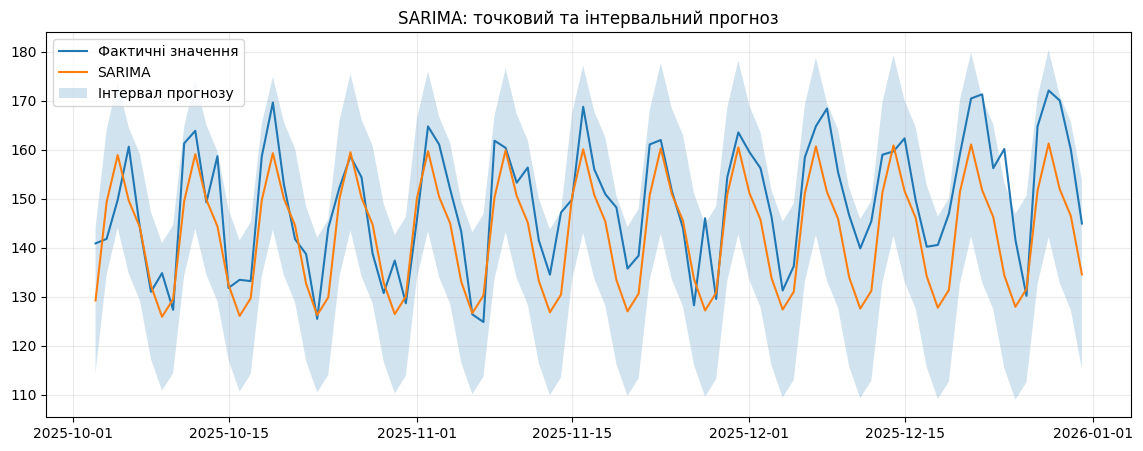

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [ ]:
# Ваш код тут

sarima_new = SARIMAX(
    train["sales"],
    order=(2, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_new_pred = sarima_new.forecast(steps=len(test))

sarima_new_metrics = evaluate(
    test["sales"],
    sarima_new_pred,
    train["sales"],
    seasonality=7
)

sarima_results = pd.DataFrame({
    "Попередня SARIMA": sarima_metrics,
    "Нова SARIMA": sarima_new_metrics
}).T

display(sarima_results[["MAE", "RMSE"]])

print("Краща модель за MAE:", sarima_results["MAE"].idxmin())
print("Краща модель за RMSE:", sarima_results["RMSE"].idxmin())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,MAE,RMSE
Попередня SARIMA,7.746566,9.401756
Нова SARIMA,8.092037,9.663575


Краща модель за MAE: Попередня SARIMA
Краща модель за RMSE: Попередня SARIMA


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [ ]:
!pip -q install prophet

In [ ]:
# Розкоментуйте, якщо Prophet встановлений.

# from prophet import Prophet
#
# prophet_train = (
#     train.reset_index()
#          .rename(columns={"date": "ds", "sales": "y"})
# )
#
# model_prophet = Prophet(
#     weekly_seasonality=True,
#     yearly_seasonality=True,
#     daily_seasonality=False,
#     seasonality_mode="additive"
# )
#
# model_prophet.fit(prophet_train)
#
# future = model_prophet.make_future_dataframe(
#     periods=len(test),
#     freq="D"
# )
#
# forecast = model_prophet.predict(future)
#
# prophet_pred = (
#     forecast.set_index("ds")
#             .loc[test.index, "yhat"]
# )
#
# evaluate(
#     test["sales"],
#     prophet_pred,
#     train["sales"],
#     seasonality=7
# )

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

,MAE,RMSE,sMAPE_%,MASE
Prophet,5.301959,6.437513,3.619983,0.747886


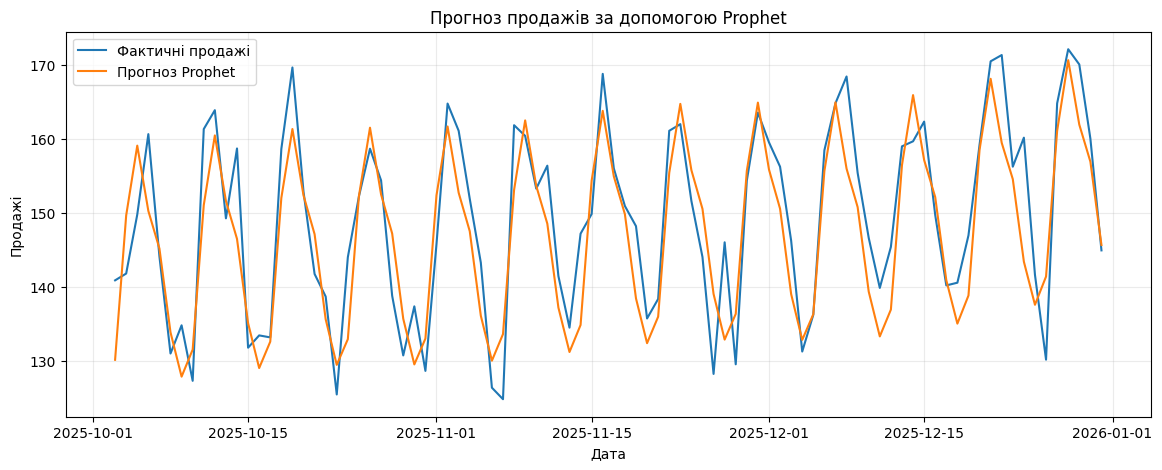

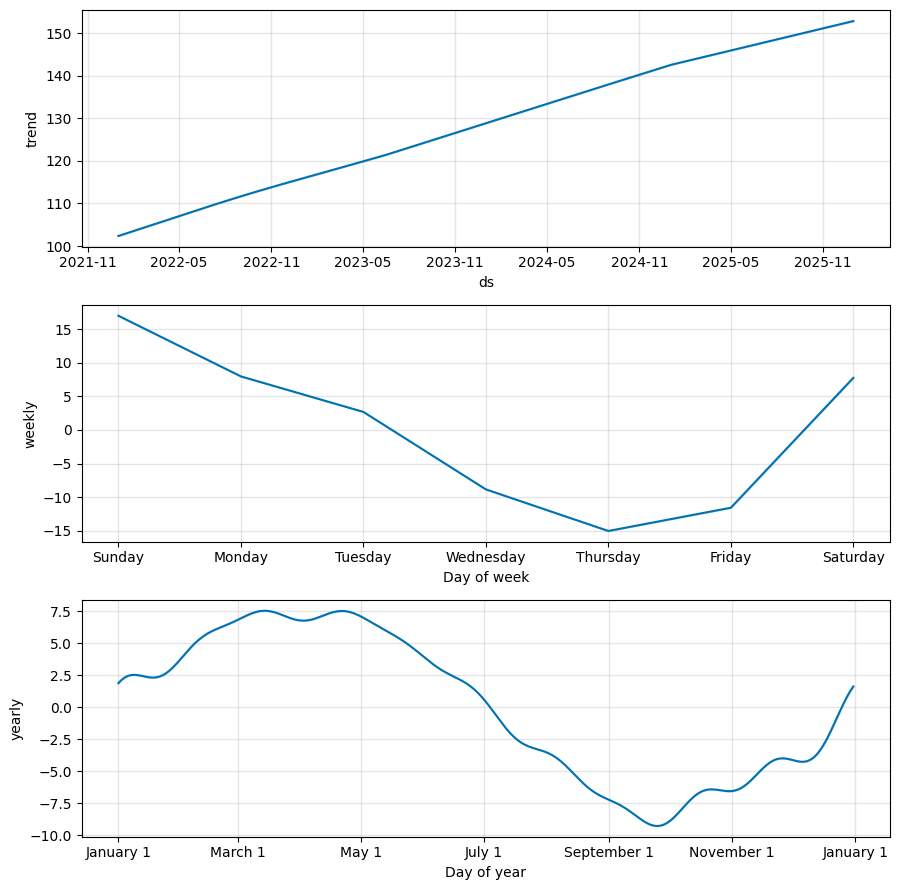

,MAE,RMSE,sMAPE_%,MASE
ETS,13.114526,15.229021,9.149617,1.849915
SARIMA,7.746566,9.401756,5.302246,1.092719
Prophet,5.301959,6.437513,3.619983,0.747886


Найкраща модель за MAE: Prophet


In [ ]:
# Ваш код тут

try:
    from prophet import Prophet

    prophet_data = train.reset_index().rename(
        columns={"date": "ds", "sales": "y"}
    )

    prophet_model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="additive"
    )

    prophet_model.fit(prophet_data)

    future_dates = prophet_model.make_future_dataframe(
        periods=len(test),
        freq="D"
    )

    forecast = prophet_model.predict(future_dates)
    prophet_pred = forecast.set_index("ds").loc[test.index, "yhat"]

    prophet_metrics = evaluate(
        test["sales"],
        prophet_pred,
        train["sales"],
        seasonality=7
    )

    display(pd.DataFrame({
        "Prophet": prophet_metrics
    }).T)

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(test.index, test["sales"], label="Фактичні продажі")
    ax.plot(test.index, prophet_pred, label="Прогноз Prophet")
    ax.set_title("Прогноз продажів за допомогою Prophet")
    ax.set_xlabel("Дата")
    ax.set_ylabel("Продажі")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

    prophet_model.plot_components(forecast)
    plt.show()

    comparison = pd.DataFrame({
        "ETS": ets_metrics,
        "SARIMA": sarima_metrics,
        "Prophet": prophet_metrics
    }).T

    display(comparison)

    print("Найкраща модель за MAE:", comparison["MAE"].idxmin())

except ImportError:
    prophet_metrics = None
    print("Встановіть бібліотеку командою %pip install prophet і повторно запустіть комірку.")

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [ ]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [ ]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 6.4256724041518165,
 'RMSE': np.float64(7.708139982015866),
 'sMAPE_%': np.float64(4.411484230090363),
 'MASE': np.float64(0.9063953646912981)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [ ]:
# Ваш код тут

def create_features(series):
    data = pd.DataFrame({"sales": series})

    data["lag_21"] = data["sales"].shift(21)
    data["rolling_mean_14"] = data["sales"].shift(1).rolling(14).mean()
    data["week_of_year"] = data.index.isocalendar().week.astype(int)

    data["lag_7"] = data["sales"].shift(7)
    data["lag_14"] = data["sales"].shift(14)
    data["day_of_week"] = data.index.dayofweek
    data["month"] = data.index.month

    return data

features_df = create_features(df["sales"]).dropna()

train_features = features_df.loc[features_df.index < test.index.min()]
test_features = features_df.loc[features_df.index >= test.index.min()]

X_train = train_features.drop(columns="sales")
y_train = train_features["sales"]
X_test = test_features.drop(columns="sales")
y_test = test_features["sales"]

model_features = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

model_features.fit(X_train, y_train)
feature_pred = model_features.predict(X_test)

feature_metrics = evaluate(
    y_test,
    feature_pred,
    train["sales"],
    seasonality=7
)

feature_comparison = pd.DataFrame({
    "Початкова модель": ml_metrics,
    "Модель з новими ознаками": feature_metrics
}).T

display(feature_comparison)

print("Краща модель за MAE:", feature_comparison["MAE"].idxmin())

print(
    "Календарні ознаки відомі заздалегідь. "
    "Лаги та ковзне середнє використовують попередні значення продажів. "
    "Однак під час прогнозування всього тестового періоду фактичні продажі "
    "попередніх днів тесту не завжди доступні. Тому для багатокрокового "
    "прогнозу потрібно використовувати прогнозовані значення або окрему стратегію прогнозування."
)

,MAE,RMSE,sMAPE_%,MASE
Початкова модель,6.425672,7.708140,4.411484,0.906395
Модель з новими ознаками,6.208894,7.660334,4.227998,0.875817


Краща модель за MAE: Модель з новими ознаками
Календарні ознаки відомі заздалегідь. Лаги та ковзне середнє використовують попередні значення продажів. Однак під час прогнозування всього тестового періоду фактичні продажі попередніх днів тесту не завжди доступні. Тому для багатокрокового прогнозу потрібно використовувати прогнозовані значення або окрему стратегію прогнозування.


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [ ]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,6.425672,7.708140,4.411484,0.906395
Seasonal naive,7.734062,9.380056,5.276847,1.090955
SARIMA,7.746566,9.401756,5.302246,1.092719
ETS,13.114526,15.229021,9.149617,1.849915
Naive,22.039691,25.297086,15.570350,3.108885


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

Найменший MAE показала ML-модель, яка виявилася точнішою за seasonal naive. Висновки за всіма метриками загалом узгоджуються, але кожна з них оцінює помилки по-різному. Для практичного використання я б обрала ML-модель із розширеними ознаками, оскільки вона показала найкращий результат, але враховувала б доступність даних під час прогнозування.


## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [ ]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [ ]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

Середня MAE для 28 днів: 7.299
Середня MAE для 14 днів: 7.299


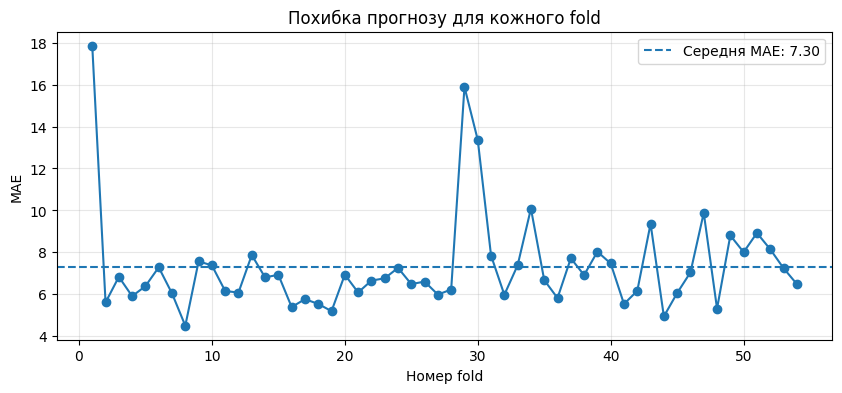

In [ ]:
# Ваш код тут

cv_results_14 = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=14,
    step=14,
    seasonality=7
)

mean_mae_28 = cv_results["MAE"].mean()
mean_mae_14 = cv_results_14["MAE"].mean()

print("Середня MAE для 28 днів:", round(mean_mae_28, 3))
print("Середня MAE для 14 днів:", round(mean_mae_14, 3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(cv_results_14) + 1), cv_results_14["MAE"], marker="o")
ax.axhline(mean_mae_14, linestyle="--", label=f"Середня MAE: {mean_mae_14:.2f}")
ax.set_title("Похибка прогнозу для кожного fold")
ax.set_xlabel("Номер fold")
ax.set_ylabel("MAE")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

Покриття прогнозного інтервалу: 96.67%
Кількість значень в інтервалі: 87 із 90


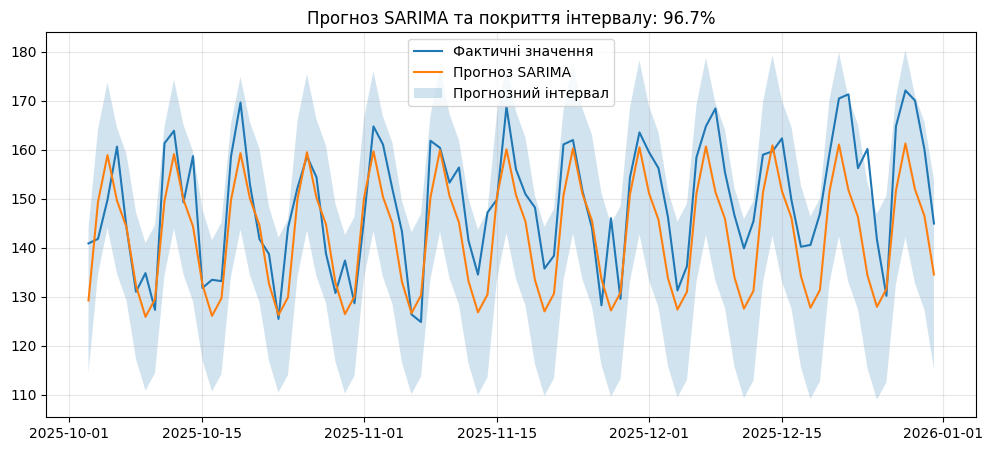

In [ ]:
# Ваш код тут

lower = sarima_ci.iloc[:, 0]
upper = sarima_ci.iloc[:, 1]
actual = test["sales"]

inside = (actual >= lower) & (actual <= upper)
coverage = inside.mean()

print(f"Покриття прогнозного інтервалу: {coverage:.2%}")
print(f"Кількість значень в інтервалі: {inside.sum()} із {len(inside)}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, actual, label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="Прогноз SARIMA")
ax.fill_between(
    test.index, lower.values, upper.values,
    alpha=0.2, label="Прогнозний інтервал"
)

ax.set_title(f"Прогноз SARIMA та покриття інтервалу: {coverage:.1%}")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [ ]:
# 1. Первинний аналіз
# Ваш код тут

print(df.head())
print(df.info())

print("Кількість спостережень:", len(df))
print("Період даних:", df.index.min(), "-", df.index.max())
print("Пропуски:\n", df.isnull().sum())
print("Кількість дублікатів дат:", df.index.duplicated().sum())
print(df["sales"].describe())

                 sales
date                  
2022-01-01  112.980285
2022-01-02  118.725005
2022-01-03  115.930451
2022-01-04  114.862459
2022-01-05   94.078518
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1461 entries, 2022-01-01 to 2025-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sales   1461 non-null   float64
dtypes: float64(1)
memory usage: 55.1 KB
None
Кількість спостережень: 1461
Період даних: 2022-01-01 00:00:00 - 2025-12-31 00:00:00
Пропуски:
 sales    0
dtype: int64
Кількість дублікатів дат: 0
count    1461.000000
mean      128.866427
std        19.950851
min        78.054031
25%       114.829619
50%       128.296899
75%       142.596785
max       279.572480
Name: sales, dtype: float64


In [ ]:
# 2. Підготовка даних
# Ваш код тут

df = df.sort_index()

date_diff = df.index.to_series().diff().dropna()

print("Кількість пропусків у продажах:", df["sales"].isnull().sum())
print("Інтервали між датами:\n", date_diff.value_counts())
print("Регулярність часової шкали:",
      (date_diff == pd.Timedelta(days=1)).all())

Кількість пропусків у продажах: 0
Інтервали між датами:
 date
1 days    1460
Name: count, dtype: int64
Регулярність часової шкали: True


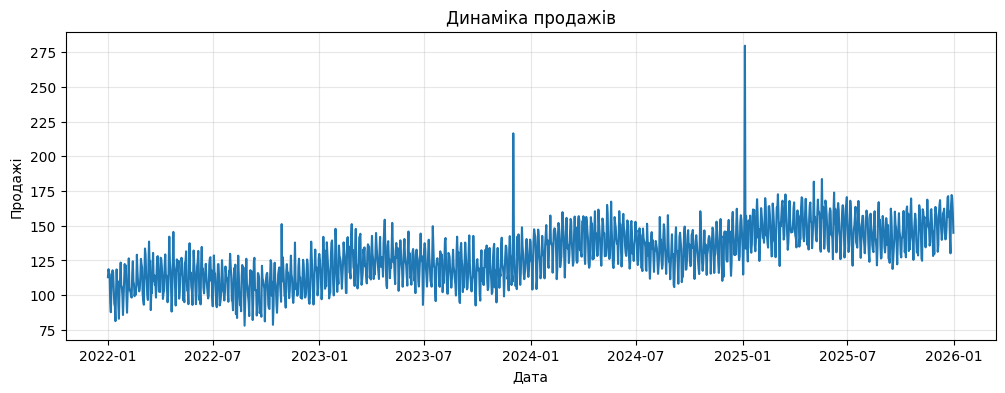

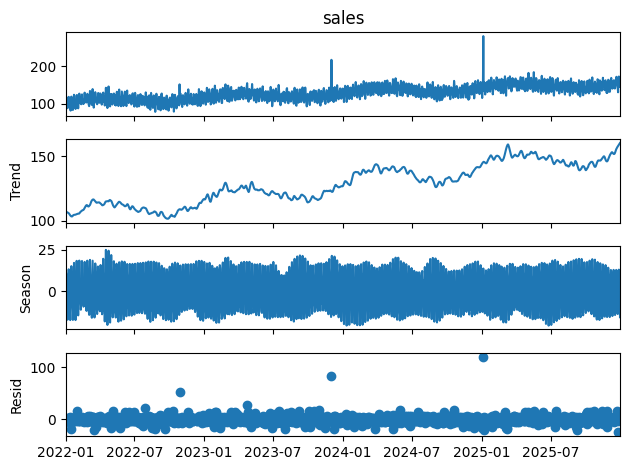

In [ ]:
# 3. Візуалізація та STL
# Ваш код тут

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["sales"])
plt.title("Динаміка продажів")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.grid(alpha=0.3)
plt.show()

# STL-декомпозиція
from statsmodels.tsa.seasonal import STL

stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()
stl_result.plot()
plt.show()

In [ ]:
# 4. Train/test split
# Ваш код тут

train = df["sales"].iloc[:-60]
test = df["sales"].iloc[-60:]

print("Кількість значень train:", len(train))
print("Кількість значень test:", len(test))
print("Початок тестового періоду:", test.index.min())
print("Кінець тестового періоду:", test.index.max())

Кількість значень train: 1401
Кількість значень test: 60
Початок тестового періоду: 2025-11-02 00:00:00
Кінець тестового періоду: 2025-12-31 00:00:00


In [ ]:
# 5. Seasonal naive baseline
# Ваш код тут
seasonal_naive_pred = pd.Series(
    [train.iloc[-7 + i % 7] for i in range(len(test))],
    index=test.index
)

print("MAE seasonal naive:",
      round(mean_absolute_error(test, seasonal_naive_pred), 3))

MAE seasonal naive: 10.162


In [ ]:
# 6. Статистична модель
# Ваш код тут

from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = model.fit(disp=False)
sarima_pred = sarima_fit.forecast(steps=len(test))
sarima_pred.index = test.index

print("MAE SARIMA:", round(mean_absolute_error(test, sarima_pred), 3))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


MAE SARIMA: 7.292


In [ ]:
# 7. ML-модель
# Ваш код тут

from sklearn.ensemble import RandomForestRegressor

def create_features(series):
    data = pd.DataFrame({"sales": series})
    for lag in [1, 7, 14, 28]:
        data[f"lag_{lag}"] = data["sales"].shift(lag)
    data["day_of_week"] = data.index.dayofweek
    return data.dropna()

train_features = create_features(train)
X_train = train_features.drop(columns="sales")
y_train = train_features["sales"]

ml_model = RandomForestRegressor(n_estimators=200, random_state=42)
ml_model.fit(X_train, y_train)

history = train.copy()
ml_predictions = []

for date in test.index:
    features = [
        history.iloc[-lag] for lag in [1, 7, 14, 28]
    ] + [date.dayofweek]

    prediction = ml_model.predict(
        pd.DataFrame(
            [features],
            columns=X_train.columns
        )
    )[0]

    ml_predictions.append(prediction)
    history.loc[date] = prediction

ml_pred = pd.Series(ml_predictions, index=test.index)

print("MAE Random Forest:",
      round(mean_absolute_error(test, ml_pred), 3))

MAE Random Forest: 9.17


In [ ]:
# 8. Порівняння метрик
# Ваш код тут
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(actual, predicted, train_data):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    denominator = (np.abs(actual) + np.abs(predicted)).replace(0, 1e-8)
    smape = (200 * np.abs(actual - predicted) / denominator).mean()

    scale = np.abs(train_data.iloc[7:].values - train_data.iloc[:-7].values).mean()
    mase = mae / scale if scale != 0 else np.nan

    return [mae, rmse, smape, mase]

comparison = pd.DataFrame({
    "Seasonal naive": calculate_metrics(test, seasonal_naive_pred, train),
    "SARIMA": calculate_metrics(test, sarima_pred, train),
    "Random Forest": calculate_metrics(test, ml_pred, train)
}, index=["MAE", "RMSE", "sMAPE", "MASE"]).T

print(comparison.round(3).sort_values("MAE"))

                   MAE    RMSE  sMAPE   MASE
SARIMA           7.292   8.695  4.940  1.025
Random Forest    9.170  11.088  6.267  1.289
Seasonal naive  10.162  11.991  6.924  1.429


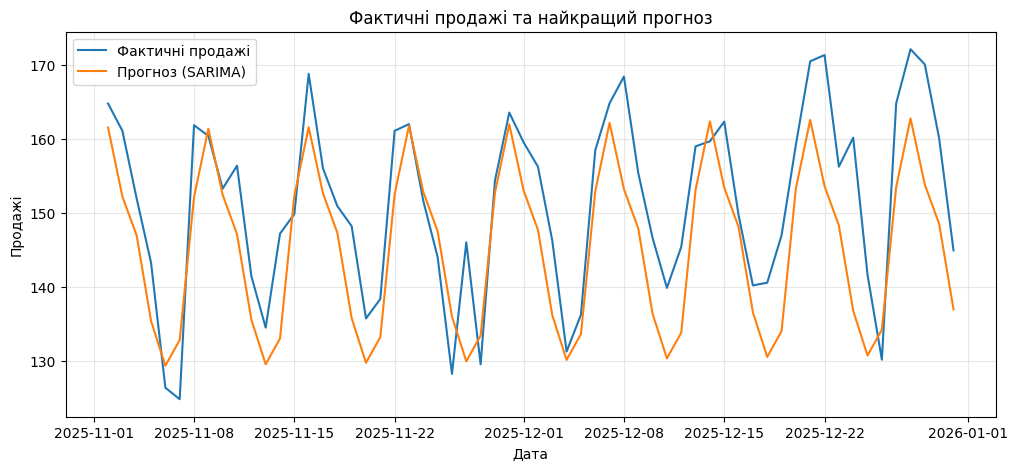

Найкраща модель: SARIMA
MAE: 7.292


In [ ]:
# 9. Фінальний графік
# Ваш код тут

predictions = {
    "Seasonal naive": seasonal_naive_pred,
    "SARIMA": sarima_pred,
    "Random Forest": ml_pred
}

best_model = comparison["MAE"].idxmin()
best_pred = predictions[best_model]

plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Фактичні продажі")
plt.plot(best_pred.index, best_pred, label=f"Прогноз ({best_model})")

plt.title("Фактичні продажі та найкращий прогноз")
plt.xlabel("Дата")
plt.ylabel("Продажі")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Найкраща модель:", best_model)
print("MAE:", round(comparison.loc[best_model, "MAE"], 3))

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

У роботі було проаналізовано часовий ряд із 1461 спостереженням без пропусків і нерегулярних дат. Для прогнозування використано моделі Seasonal Naive, SARIMA та Random Forest. Найкращою виявилася SARIMA з MAE 7,292, що на 28,2% менше, ніж у базової моделі Seasonal Naive. Порівняння моделей показало, що SARIMA забезпечила найточніший прогноз на тестовій вибірці. Водночас точність прогнозу залежить від сезонності та можливих змін у майбутніх продажах.

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?